## 01 - Exploratory Data Analysis (EDA)
- Target `visit`
- Sanity & Randomization Check
- Hubungan Fitur dan Target

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

## Dataset

- **Sumber:** MineThatData E-Mail Analytics Challenge (Kevin Hillstrom, 2008)
- **Ukuran:** ≈ 64.000 customer, 12 kolom, 1 baris = 1 customer (tanpa kolom ID)
- **Desain:** eksperimen acak, 3 grup berukuran kira-kira sama
- **Konteks bisnis:** anonim. Retailer produk pria dan wanita, multichannel (Phone/Web/Multichannel)

### Data Dictionary

| Kolom | Tipe | Deskripsi |
|---|---|---|
| `recency` | numerik (1-12) | Bulan sejak pembelian terakhir |
| `history_segment` | kategorikal ordinal | Kelompok nilai belanja 12 bulan terakhir |
| `history` | numerik (USD) | Nilai belanja aktual 12 bulan terakhir |
| `mens` | biner (0/1) | Pernah beli produk pria dalam 12 bulan terakhir |
| `womens` | biner (0/1) | Pernah beli produk wanita dalam 12 bulan terakhir |
| `zip_code` | kategorikal | Urban / Suburban / Rural |
| `newbie` | biner (0/1) | Customer baru dalam 12 bulan terakhir |
| `channel` | kategorikal | Phone / Web / Multichannel |
| `segment` | kategorikal | Mens E-Mail / Womens E-Mail / No E-Mail |
| `visit` | biner (0/1) | Kunjungan ke situs dalam 2 minggu setelah email |
| `conversion` | biner (0/1) | Pembelian dalam 2 minggu setelah email |
| `spend` | numerik (USD) | Nominal belanja dalam 2 minggu setelah email |

In [2]:
ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data" / "Kevin_Hillstrom_Dataset.csv").squeeze("columns")

In [3]:
df

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
63995,10,2) $100 - $200,105.54,1,0,Urban,0,Web,Mens E-Mail,0,0,0.0
63996,5,1) $0 - $100,38.91,0,1,Urban,1,Phone,Mens E-Mail,0,0,0.0
63997,6,1) $0 - $100,29.99,1,0,Urban,1,Phone,Mens E-Mail,0,0,0.0
63998,1,5) $500 - $750,552.94,1,0,Surburban,1,Multichannel,Womens E-Mail,0,0,0.0


In [4]:
sns.set_theme(style="whitegrid")

# EDA Hillstrom Email Marketing: Uplift Modeling (target `visit`)

---

## Tujuan dan setup

**Pertanyaan:** apakah email menaikkan kemungkinan pelanggan visit, dan apakah efeknya berbeda antar pelanggan?

**Dua setup perbandingan**
- **A (biner):** any email vs control
- **B (multi-treatment):** Mens vs control, Womens vs control (plus Mens vs Womens di level ATE)

**Data:** 64.000 pelanggan, kira-kira sepertiga per arm (`segment`: No E-Mail = control, Mens E-Mail, Womens E-Mail).

**Catatan fitur**
- `mens` / `womens` adalah **fitur riwayat pembelian** (pernah beli kategori itu atau tidak), **bukan treatment**. Keduanya tidak saling eksklusif. Jangan tertukar dengan kolom `segment`.
- `conversion` dan `spend` adalah variabel **pasca-treatment**, tidak dipakai sebagai fitur (leakage).
- `history_segment` diduga turunan dari `history` (redundan).

---

In [5]:
TARGET = "visit"
ARM_COL = "segment"
CTRL, TR1, TR2 = "No E-Mail", "Mens E-Mail", "Womens E-Mail"
NUM = ["recency", "history"]
CAT = ["history_segment", "zip_code", "channel"]
BIN = ["mens", "womens", "newbie"]
POST = ["conversion", "spend"]  # pasca-treatment: JANGAN jadi fitur

df = df.copy()
assert set(df[ARM_COL].unique()) == {CTRL, TR1, TR2}, "cek nama arm di kolom segment"

## 1. Sanity check

In [6]:
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])
print(df[ARM_COL].value_counts(normalize=True).round(3))
print(df.dtypes)

(64000, 12)
Series([], dtype: int64)
segment
Womens E-Mail    0.334
Mens E-Mail      0.333
No E-Mail        0.333
Name: proportion, dtype: float64
recency              int64
history_segment        str
history            float64
mens                 int64
womens               int64
zip_code               str
newbie               int64
channel                str
segment                str
visit                int64
conversion           int64
spend              float64
dtype: object


## 2. Randomization check
Tujuan: memastikan grup setara sebelum perlakuan, sehingga selisih outcome bisa dibaca sebagai efek kausal.
Kenapa: asumsi uplift = grup awalnya setara. |SMD| < 0.1 dianggap aman.
Dengan banyak uji, 1 p < 0.05 kebetulan itu wajar, lihat polanya, bukan satu angka.

In [7]:
def smd(x_t, x_c):
    s = np.sqrt((x_t.var() + x_c.var()) / 2)
    return (x_t.mean() - x_c.mean()) / s if s > 0 else 0.0

rows = []
for arm in [TR1, TR2]:
    for c in NUM + BIN:
        rows.append((arm, c, smd(df.loc[df[ARM_COL] == arm, c],
                                 df.loc[df[ARM_COL] == CTRL, c])))
bal = pd.DataFrame(rows, columns=["arm", "feature", "smd"]).pivot(
    index="feature", columns="arm", values="smd")
print("SMD vs control:\n", bal.round(3))

for c in CAT:
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(df[c], df[ARM_COL]))
    print(f"{c}: chi2 p = {p:.3f}")


SMD vs control:
 arm      Mens E-Mail  Womens E-Mail
feature                            
history        0.008          0.007
mens          -0.005         -0.009
newbie        -0.001          0.003
recency        0.007          0.005
womens         0.008          0.005
history_segment: chi2 p = 0.358
zip_code: chi2 p = 0.579
channel: chi2 p = 0.458



| Fitur | SMD (Mens vs ctrl) | SMD (Womens vs ctrl) |
|---|---|---|
| history | 0.008 | 0.007 |
| mens | -0.005 | -0.009 |
| newbie | -0.001 | 0.003 |
| recency | 0.007 | 0.005 |
| womens | 0.008 | 0.005 |

Chi-square (distribusi kategori vs arm): `history_segment` p = 0.358, `zip_code` p = 0.579, `channel` p = 0.458.

**Temuan:** semua |SMD| < 0.01 (batas konvensi 0.1) dan tidak ada p yang signifikan. Konsisten dengan randomisasi yang sehat.

**Batasan:** check ini hanya marginal (satu fitur per satu) dan hanya untuk fitur yang teramati. Jaminan utamanya datang dari desain eksperimen, check ini hanya konfirmasi. Pengecekan yang lebih menyeluruh (opsional): latih classifier untuk memprediksi arm dari semua fitur, AUC mendekati 0.5 berarti sehat.

---

## 3. Efek rata-rata (ATE) terhadap `visit`

In [8]:
def ate(d, t_mask, c_mask, y=TARGET):
    yt, yc = d.loc[t_mask, y], d.loc[c_mask, y]
    pt, pc = yt.mean(), yc.mean()
    se = np.sqrt(pt * (1 - pt) / len(yt) + pc * (1 - pc) / len(yc))
    diff = pt - pc
    return dict(n_t=len(yt), n_c=len(yc), rate_t=pt, rate_c=pc, uplift=diff,
                ci_low=diff - 1.96 * se, ci_high=diff + 1.96 * se,
                rel_lift=diff / pc if pc > 0 else np.nan,
                p=2 * (1 - stats.norm.cdf(abs(diff / se))))

a = df[ARM_COL]
comps = {
    "any_email vs ctrl": (a != CTRL, a == CTRL),
    "mens vs ctrl": (a == TR1, a == CTRL),
    "womens vs ctrl": (a == TR2, a == CTRL),
    "mens vs womens": (a == TR1, a == TR2),
}
ate_tbl = pd.DataFrame({k: ate(df, *v) for k, v in comps.items()}).T
print(ate_tbl.round(4))

                       n_t      n_c  rate_t  rate_c  uplift  ci_low  ci_high  \
any_email vs ctrl  42694.0  21306.0  0.1670  0.1062  0.0609  0.0554   0.0663   
mens vs ctrl       21307.0  21306.0  0.1828  0.1062  0.0766  0.0700   0.0832   
womens vs ctrl     21387.0  21306.0  0.1514  0.1062  0.0452  0.0389   0.0516   
mens vs womens     21307.0  21387.0  0.1828  0.1514  0.0314  0.0243   0.0384   

                   rel_lift    p  
any_email vs ctrl    0.5735  0.0  
mens vs ctrl         0.7214  0.0  
womens vs ctrl       0.4261  0.0  
mens vs womens       0.2071  0.0  



| Perbandingan | rate treatment | rate control | uplift (poin) | CI 95% | rel. lift |
|---|---|---|---|---|---|
| any email vs ctrl | 0.1670 | 0.1062 | **+0.0609** | 0.0554 – 0.0663 | 0.574 |
| Mens vs ctrl | 0.1828 | 0.1062 | **+0.0766** | 0.0700 – 0.0832 | 0.721 |
| Womens vs ctrl | 0.1514 | 0.1062 | **+0.0452** | 0.0389 – 0.0516 | 0.426 |
| Mens vs Womens | 0.1828 | 0.1514 | **+0.0314** | 0.0243 – 0.0384 | 0.207 |

**Temuan**
1. Email efektif menaikkan visit: semua CI jauh dari 0. Per 100 email, sekitar 6 sampai 8 visit tambahan.
2. Mens lebih kuat daripada Womens secara rata-rata: selisih +3,1 poin dengan CI yang tidak menyentuh 0.
3. Angka "any email" (+6,1) hanyalah rata-rata dari dua efek yang berbeda (+7,7 dan +4,5). Pooling menyembunyikan perbedaan itu.

Catatan: `rel_lift` bergantung pada basis (rate control), dan basis berbeda antar baris. Pakai uplift absolut sebagai angka utama.  
Semua angka di atas adalah rata-rata untuk seluruh pelanggan. Tabel ini tidak bisa bilang apakah efeknya sama untuk semua orang, atau ada kelompok yang responsnya jauh lebih besar (atau bahkan nol).  

---

## 4. Funnel: visit -> conversion 
conv_given_visit dihitung di antara visitor = post-treatment selection,
jadi bukan efek kausal. Gunanya cuma menguji apakah visit layak jadi proxy.

In [9]:
funnel = df.groupby(ARM_COL).agg(n=(TARGET, "size"), visit=(TARGET, "mean"),
                                 conv=("conversion", "mean"))
vis = (df[df[TARGET] == 1].groupby(ARM_COL)["conversion"]
       .agg(["size", "mean"])
       .rename(columns={"size": "n_visitors", "mean": "conv_given_visit"}))
print(funnel.join(vis).round(4))
print("konversi tanpa visit:", int(((df.conversion == 1) & (df[TARGET] == 0)).sum()))

                   n   visit    conv  n_visitors  conv_given_visit
segment                                                           
Mens E-Mail    21307  0.1828  0.0125        3894            0.0686
No E-Mail      21306  0.1062  0.0057        2262            0.0539
Womens E-Mail  21387  0.1514  0.0088        3238            0.0584
konversi tanpa visit: 0


| Arm | visit | conversion | conv \| visit |
|---|---|---|---|
| Mens | 0,1828 | 0,0125 | 0,0686 |
| Womens | 0,1514 | 0,0088 | 0,0584 |
| Control | 0,1062 | 0,0057 | 0,0539 |

- Tidak ada conversion tanpa visit (0 kasus), jadi visit adalah gerbang conversion.
- Email menaikkan conversion secara kausal: Mens ≈ +0,68 poin, Womens ≈ +0,31 poin. Sebagian besar lewat tambahan visit (sekitar 60% untuk Mens, 78% untuk Womens), jadi `visit` layak sebagai proxy.
- Conversion hanya sekitar 120 sampai 270 kejadian per arm, terlalu sedikit untuk analisis heterogenitas. Ini alasan tambahan memilih `visit` sebagai target.

Catatan: `conv | visit` bersifat deskriptif (bias seleksi), bukan efek kausal. Angka ≈ dihitung dari output yang dibulatkan.

## 5. Uplift per bin fitur
Yang dilihat: uplift (selisih rate treatment vs control) per bin + CI,
bukan response rate saja. CI yang melewati 0 = jangan dianggap sinyal.

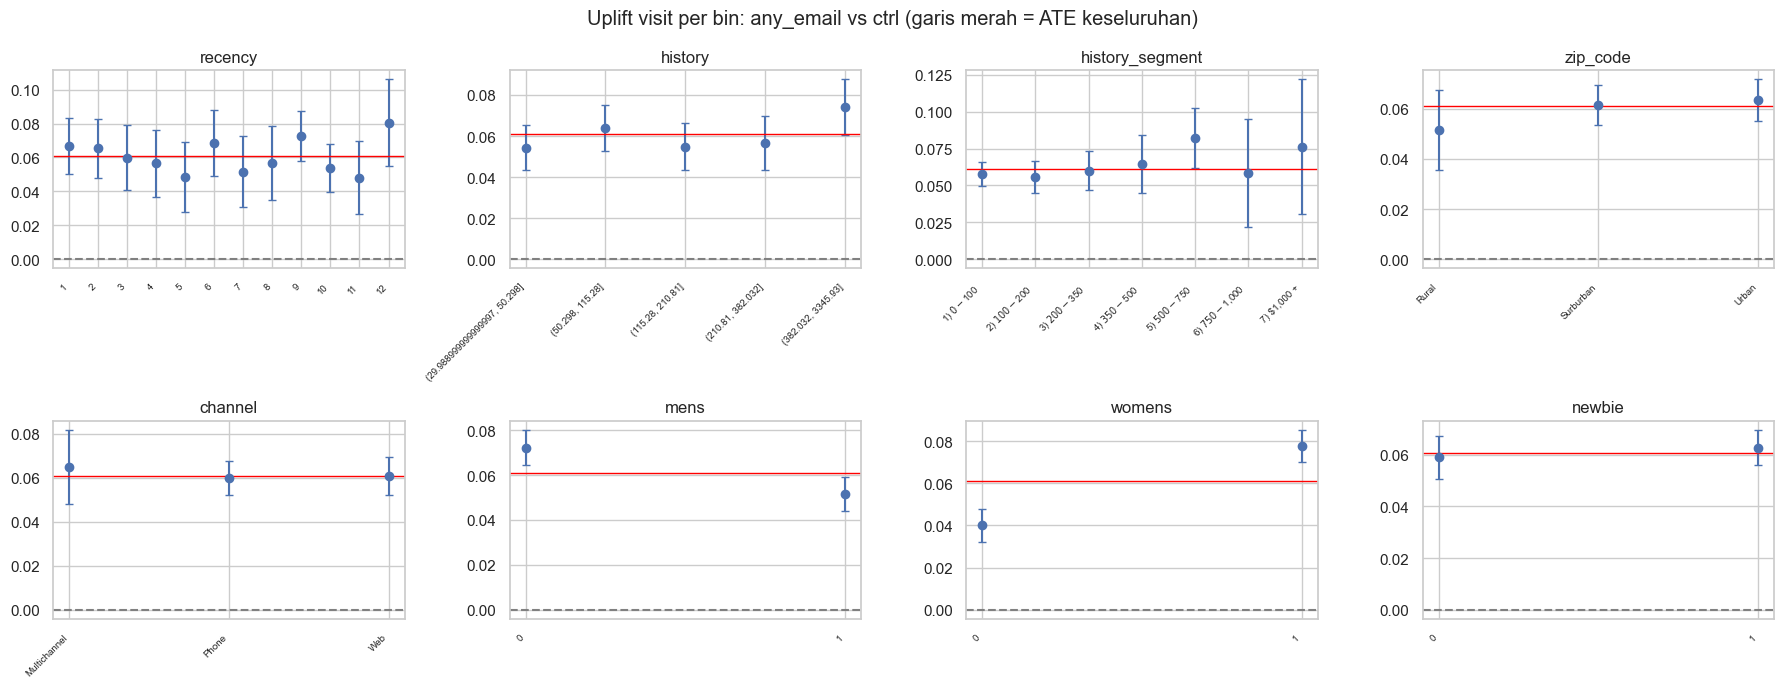

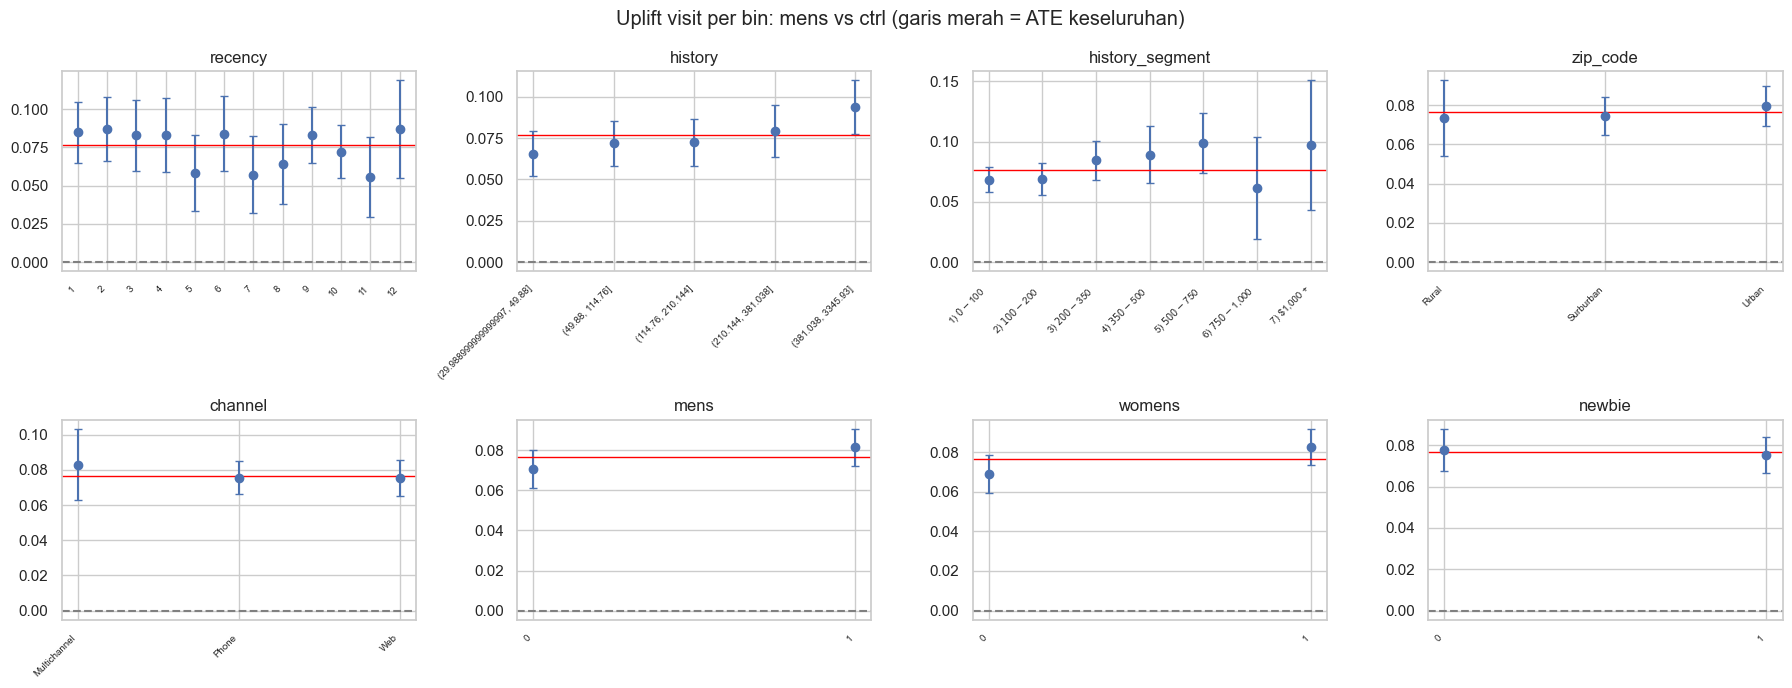

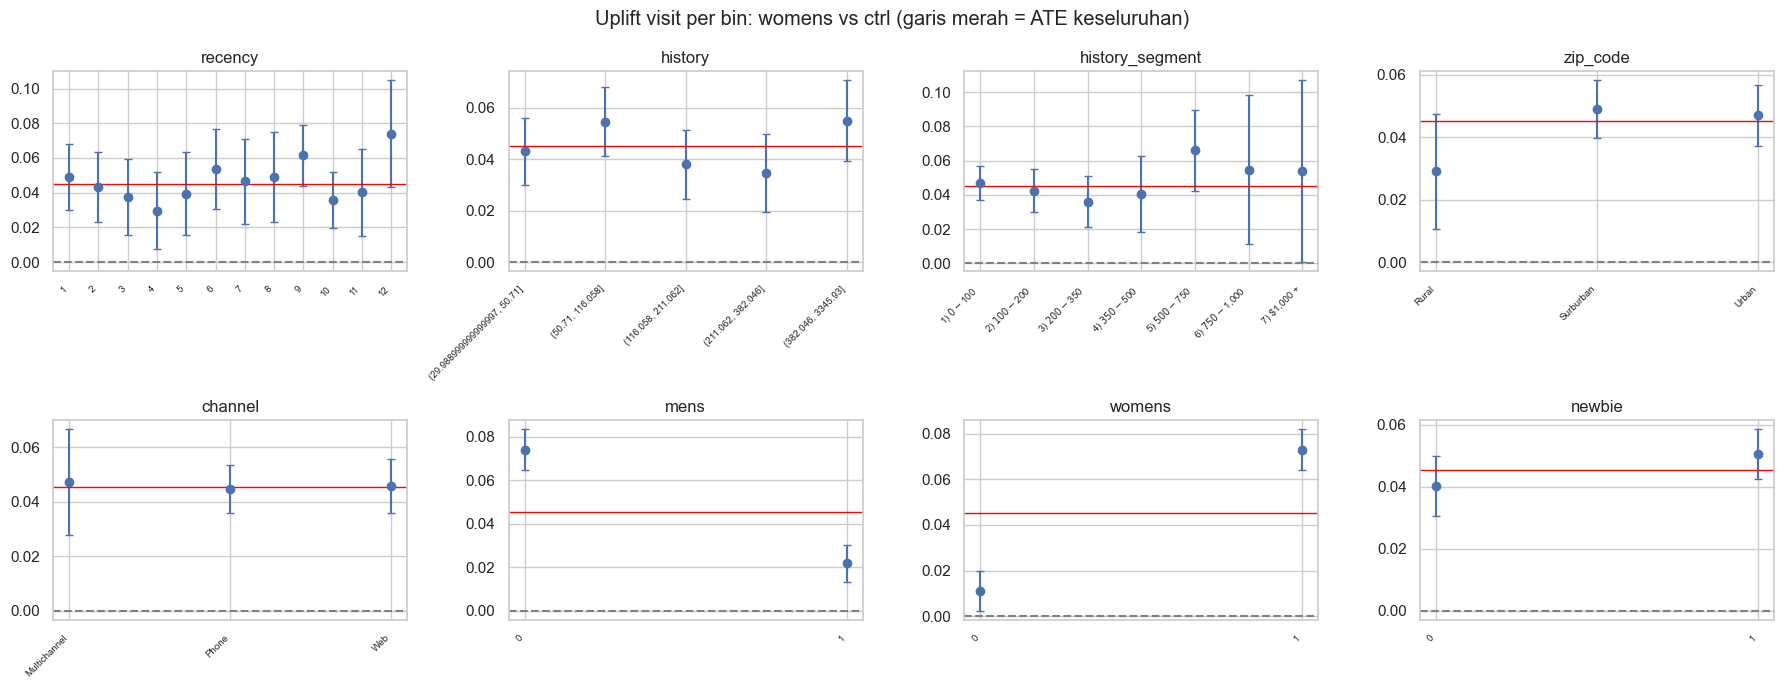

In [10]:
def uplift_by(d, col, t_mask, c_mask, q=None, y=TARGET):
    sub = d[t_mask | c_mask].copy()
    sub["_t"] = t_mask[sub.index].astype(int)
    sub["_bin"] = pd.qcut(sub[col], q, duplicates="drop") if q else sub[col]
    g = sub.groupby(["_bin", "_t"], observed=True)[y].agg(["mean", "size"]).unstack("_t")
    pt, pc = g[("mean", 1)], g[("mean", 0)]
    nt, nc = g[("size", 1)], g[("size", 0)]
    se = np.sqrt(pt * (1 - pt) / nt + pc * (1 - pc) / nc)
    out = pd.DataFrame({"n_t": nt, "n_c": nc, "rate_t": pt, "rate_c": pc,
                        "uplift": pt - pc, "se": se})
    out["ci_low"] = out.uplift - 1.96 * out.se
    out["ci_high"] = out.uplift + 1.96 * out.se
    return out

features = {"recency": None, "history": 5, "history_segment": None,
            "zip_code": None, "channel": None, "mens": None,
            "womens": None, "newbie": None}

tables = {}
for name in ["any_email vs ctrl", "mens vs ctrl", "womens vs ctrl"]:
    tm, cm = comps[name]
    overall = ate(df, tm, cm)["uplift"]
    fig, axes = plt.subplots(2, 4, figsize=(18, 7))
    fig.suptitle(f"Uplift visit per bin: {name} (garis merah = ATE keseluruhan)")
    for ax, (f, q) in zip(axes.ravel(), features.items()):
        t = uplift_by(df, f, tm, cm, q)
        tables[(name, f)] = t
        x = np.arange(len(t))
        ax.errorbar(x, t.uplift, yerr=1.96 * t.se, fmt="o", capsize=3)
        ax.axhline(0, ls="--", c="grey")
        ax.axhline(overall, c="red", lw=1)
        ax.set_xticks(x)
        ax.set_xticklabels([str(i) for i in t.index], rotation=45, ha="right", fontsize=7)
        ax.set_title(f)
    plt.tight_layout()
    plt.show()


- titik = uplift pada bin
- bar = CI 95%
- garis merah = ATE keseluruhan  

### 5.1 Satu sumber heterogenitas yang jelas: `womens` dan `mens`

| Irisan | Mens vs ctrl | Womens vs ctrl | any email vs ctrl |
|---|---|---|---|
| womens = 0 | ≈ 0.069 | **≈ 0.011** | ≈ 0.040 |
| womens = 1 | ≈ 0.083 | ≈ 0.072 | ≈ 0.078 |
| mens = 0 | ≈ 0.071 | ≈ 0.073 | ≈ 0.072 |
| mens = 1 | ≈ 0.082 | **≈ 0.022** | ≈ 0.052 |

**Temuan**
- **Email Womens** hampir tidak bekerja untuk pelanggan yang tidak pernah membeli produk wanita (≈ 1 poin), tetapi bekerja baik untuk yang pernah (≈ 7 poin). Pola serupa dan berkebalikan untuk `mens` = 1 (≈ 2 poin).
- **Email Mens** relatif seragam di semua irisan ini (≈ 7 sampai 8 poin), CI saling tumpang tindih.
- Pada irisan ini, Mens setara atau lebih baik daripada Womens di semua kasus: jauh lebih baik di `womens` = 0 dan `mens` = 1, tidak bisa dibedakan di `womens` = 1 dan `mens` = 0 (CI tumpang tindih).

### 5.2 Konsistensi dengan setup biner

Karena ketiga arm berukuran hampir sama, uplift pooled ≈ rata-rata uplift kedua arm. Contoh: `womens` = 0 → (0.069 + 0.011) / 2 ≈ 0.040, cocok dengan plot any email. Artinya **heterogenitas yang terlihat di setup biner hampir seluruhnya berasal dari arm Womens**. Ini efek spesifik per arm yang tercampur karena pooling.

### 5.3 Fitur lain: tidak ada bukti heterogenitas

`recency`, `history`, `history_segment`, `zip_code`, `channel`, `newbie`: CI hampir selalu tumpang tindih dengan garis merah di ketiga perbandingan.

Pola yang sempat terlihat, dan statusnya:
- Arm Mens: uplift cenderung naik seiring `history` (≈ 0.065 → 0.094 di 5 kuantil). Lemah dan tidak monoton di `history_segment`. **Hipotesis**, bukan temuan.
- Arm Womens, `zip_code` = Rural (≈ 0.029, CI lebar): grup kecil, CI hampir menyentuh garis merah. Tidak cukup bukti.

Dengan 3 perbandingan × 8 fitur × banyak bin, ada ratusan CI. Beberapa pasti keluar jalur karena kebetulan. Pola `womens`/`mens` jauh melampaui itu, sedangkan sisanya tidak.

### 5.4 Catatan teknis
- Batas bin `history` dihitung dengan `qcut` di dalam fungsi, pada subset (treatment + control) masing-masing perbandingan. Akibatnya batas bin sedikit berbeda antar plot. Perbaikan: hitung bin sekali pada seluruh `df`.
- `mens` dan `womens` dilihat satu per satu, padahal tidak saling eksklusif. Tabel gabungan (mens × womens) belum dibuat.

## 6. Redundansi fitur


In [11]:
print(df.groupby("history_segment")["history"].agg(["min", "max", "size"]))
print(df[NUM].corr().round(3))
print("Fitur untuk model:", [c for c in df.columns if c not in POST + [ARM_COL, TARGET]])

                      min      max   size
history_segment                          
1) $0 - $100        29.99    99.99  22970
2) $100 - $200     100.00   199.98  14254
3) $200 - $350     200.00   349.96  12289
4) $350 - $500     350.01   499.95   6409
5) $500 - $750     500.00   749.79   4911
6) $750 - $1,000   750.01   999.75   1859
7) $1,000 +       1000.15  3345.93   1308
         recency  history
recency    1.000   -0.247
history   -0.247    1.000
Fitur untuk model: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel']


Korelasi `recency` – `history` = -0,247.

**Temuan**

1. **`history_segment` redundan.** Murni hasil binning `history`: rentang antar segmen tidak tumpang tindih dan batasnya persis sesuai label. Seluruh informasinya sudah ada di `history`, jadi dibuang dari fitur model.
2. **Segmen sangat tidak seimbang.** `history` miring ke kanan: segmen 1 berisi sekitar 36% pelanggan, segmen 7 hanya sekitar 2% (1.308 orang, sekitar 436 per arm). Ini menjelaskan CI yang lebar di segmen atas pada plot uplift per bin (bagian 5).
3. **Korelasi `recency` – `history` sedang (-0,247).** Pelanggan dengan pembelian lebih baru cenderung punya `history` lebih tinggi. Tidak mengkhawatirkan, kedua fitur dipertahankan.

**Fitur untuk model (7):** `recency`, `history`, `mens`, `womens`, `zip_code`, `newbie`, `channel`

---


## 7. Ringkasan: temuan vs hipotesis

**Temuan (didukung data)**
1. Randomisasi sehat (SMD < 0.01, chi-square tidak signifikan).
2. Email menaikkan visit: Mens ≈ +7,7 poin, Womens ≈ +4,5 poin, selisih Mens − Womens ≈ +3,1 poin.
3. Efek Womens sangat bergantung pada riwayat pembelian (`womens`, `mens`). Efek Mens relatif seragam.
4. Tidak ada bukti heterogenitas pada `recency`, `history`, `zip_code`, `channel`, `newbie`.

**Hipotesis (belum diuji)**
1. Untuk target `visit`, mengirim email Mens ke semua orang mungkin sudah hampir optimal (Mens ≥ Womens di semua irisan satu dimensi).
2. Penyebab Womens bekerja hanya pada pembeli produk wanita kemungkinan relevansi produk. Datanya tidak bisa memastikan penyebabnya.
3. Tren uplift terhadap `history` pada arm Mens.

---

## 8. Implikasi untuk modeling

- **Setup biner:** treatment-nya campuran dua email, sehingga model menjawab "siapa yang diuntungkan jika menerima salah satu dari dua email secara acak". Kemungkinan besar `womens` muncul sebagai pendorong utama, karena heterogenitas di plot biner berasal dari arm Womens. Berguna sebagai baseline dan latihan; makna operasionalnya lebih lemah daripada multi-treatment.
- **Setup multi-treatment:** heterogenitas kuat terlihat di arm Womens (berdasarkan `womens`/`mens`), tetapi masih hipotesis EDA: belum diuji formal dan belum divalidasi di hold-out.
- **Baseline evaluasi:** (1) acak, (2) "kirim Mens ke semua", (3) aturan sederhana dari `mens`/`womens`. Model uplift hanya bernilai jika mengalahkan (3), dengan selisih yang dinilai bersama ketidakpastiannya (bootstrap/CV). Jika tidak, kesimpulan yang sah adalah kebijakan yang lebih sederhana (untuk `visit`).


